<a href="https://colab.research.google.com/github/Raj-18-45/Machine-Learning/blob/main/Supervised%20Learning/Support_Vector_Machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Description:

This experiment implements Linear and Non-linear Support Vector Machine (SVM) models using the Wisconsin Diagnostic Breast Cancer Dataset. The dataset is loaded and explored, and the data is divided into training and testing sets. StandardScaler is used to scale the features before training the models. Both Linear SVM and Non-linear SVM with the RBF kernel are trained and evaluated using accuracy, confusion matrix, and Stratified K-Fold cross-validation. Finally, sample predictions are performed using both models.

In [5]:
#Import Libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
#Load and Explore Dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Missing values:", np.isnan(X).sum())

Dataset shape: (569, 30)
Missing values: 0


In [6]:
#Split into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

**Part A — Linear SVM**

In [8]:
#Create and Train the Model
linear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(C=1.0, max_iter=20000, random_state=42))
])

linear_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', LinearSVC(max_iter=20000, random_state=42))])

In [9]:
# Evaluate the Model
linear_pred = linear_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, linear_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, linear_pred))

Accuracy: 0.9649122807017544
Confusion Matrix:
 [[40  2]
 [ 2 70]]


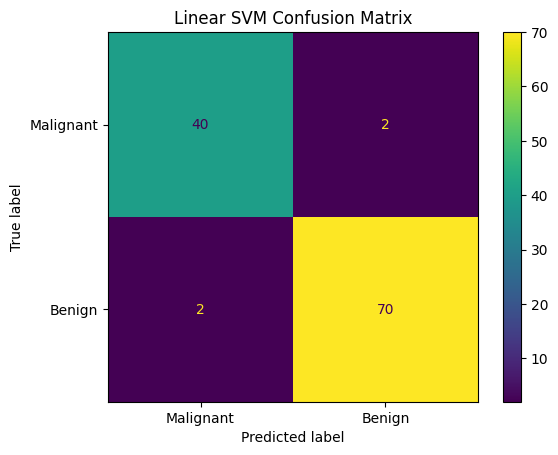

In [10]:
#Plot the Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, linear_pred,
    display_labels=["Malignant", "Benign"]
)
plt.title("Linear SVM Confusion Matrix")
plt.show()

In [11]:
#Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

linear_cv = cross_val_score(
    linear_model, X, y, cv=cv, scoring='accuracy'
)

print("Fold accuracies:", np.round(linear_cv, 4))
print("Mean accuracy:", round(linear_cv.mean(), 4))

Fold accuracies: [0.9561 0.9561 0.9561 0.9825 0.9823]
Mean accuracy: 0.9666


In [12]:
#Example Prediction
sample = X_test[[0]]

print("Actual class:", y_test[0])
print("Predicted class:", linear_model.predict(sample)[0])

Actual class: 0
Predicted class: 0


Part B — Non-linear SVM (RBF Kernel)

In [14]:
#Create and Train the Model
nonlinear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

nonlinear_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])

In [15]:
#Evaluate the Model
nonlinear_pred = nonlinear_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, nonlinear_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, nonlinear_pred))

Accuracy: 0.9824561403508771
Confusion Matrix:
 [[41  1]
 [ 1 71]]


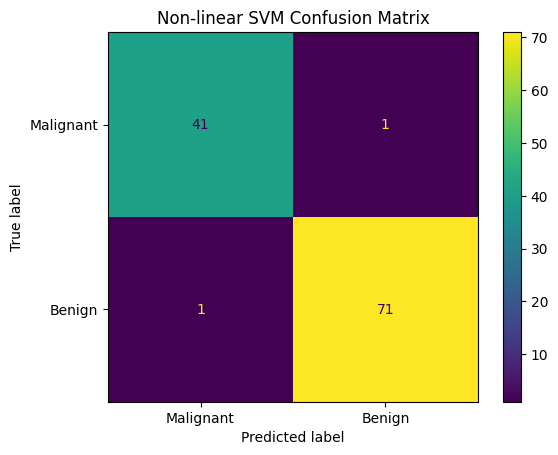

In [16]:
#Plot the Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, nonlinear_pred,
    display_labels=["Malignant", "Benign"]
)
plt.title("Non-linear SVM Confusion Matrix")
plt.show()

In [18]:
##Cross-Validation
nonlinear_cv = cross_val_score(
    nonlinear_model, X, y, cv=cv, scoring='accuracy'
)

print("Fold accuracies:", np.round(nonlinear_cv, 4))
print("Mean accuracy:", round(nonlinear_cv.mean(), 4))

Fold accuracies: [0.9912 0.9474 0.9737 0.9912 0.9823]
Mean accuracy: 0.9772


In [21]:
#Example Prediction
sample = X_test[[0]]

print("Actual class:", y_test[0])
print("Predicted class:", nonlinear_model.predict(sample)[0])

Actual class: 0
Predicted class: 0
